# `demo_crit_db`: synthetic AR(12) data, distance to $M_6$

> **NOT OWN WORK.** Python port of `demo/demo_crit_db.m` from the MATLAB *prox_crit_toolkit* by J. S. Sooter et al. ([GitHub](https://github.com/sam-sooter/prox_crit_toolkit), fetched 2026-10-09; CC BY-NC 4.0), translated by Andre Potthoff (with Claude). Text and code follow the original cell by cell; additions are marked *[port note]*. Functions: `src/analysis/prox_crit/` (see `NOTICE.md`, `FLAGS.md`).

*[port note]*
- The original's comment says "calculate d2", but the script sets `b = 6`, so it computes $d_6$; the comment is corrected here.
- The original requests error bars together with Yule-Walker fitting, a combination that always fails (error bars need the maximum likelihood fit). Since the script never uses the error bar, it is not requested here.
- FLAG 9 applies: for b ≥ 4, MATLAB's `fmincon` stops early, so the Python $d_6$ can be lower than MATLAB's.

In [1]:
%load_ext jupyter_black
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from src.analysis.prox_crit import ar_roots, calc_db, run_ar
from src.config.paths import FIGURES_DIR, RESULTS_OBJECTS

### Generating synthetic data

In [2]:
n = 12
p = 0.7
sigma = 1  # AR model parameters
if n > 6:
    kern = (-p) ** np.arange(n)  # alternating, geometrically decaying kernel
else:
    kern = p ** np.arange(n)
kern = (
    0.95 * kern / kern.sum()
)  # normalize so that the kernel sums to 0.95 (just below the critical value 1)

# However the kernel is made, it could come out explosive. Scale it down until it is stable.
minroot = np.min(np.abs(ar_roots(kern)))  # smallest |root| of 1 - sum kern_k z^k
while minroot < 1:
    kern = kern * minroot * 0.99
    minroot = np.min(np.abs(ar_roots(kern)))
    print("Adjusting kernel for stability")
print(f"kernel (lags 1-{n}): {np.array2string(kern, precision=4)}")
print(f"sum = {kern.sum():.3f}, smallest |root| = {minroot:.3f} (> 1: stable)")

T = int(1e4)  # number of time steps
x = run_ar(kern, sigma, T, rng=np.random.default_rng(seed=0))  # simulate AR model
print(f"simulated series: {x.shape}, mean {x.mean():.3f}, std {x.std():.3f}")

kernel (lags 1-12): [ 1.6377 -1.1464  0.8025 -0.5617  0.3932 -0.2752  0.1927 -0.1349  0.0944
 -0.0661  0.0463 -0.0324]
sum = 0.950, smallest |root| = 1.120 (> 1: stable)
simulated series: (10000,), mean 0.126, std 4.714


In [3]:
# d_b settings (minimal)
order = len(kern)  # AR model order
delta_t = 1  # time between consecutive steps in time series (in s)
b = 6  # calculate d6 (rather than d2, d4, ...)

# Optional arguments
dbopt = dict(
    with_err_bars=False,  # calculate error bars? [default=False] (would need fit_method="MaxLikelihood")
    with_qc=False,  # make quality control plots? [default=False]
    with_parallel=False,  # use parallel computing? [default=False]
    fit_method="YuleWalker",  # AR fit method [default='YuleWalker']
)

Keep the original kernel and sigma, i.e. return `kernf` and `sigmaf` as the fitted values. Note that the first step inside `calc_db` is to normalize `x` to unit variance.

In [4]:
db, sddb, kernf, sigmaf, H, kernc, exit_status = calc_db(x, order, delta_t, b, **dbopt)

print("original kernel:                 ", np.array2string(kern, precision=4))
print("best-fit kernel:                 ", np.array2string(kernf, precision=4))
print("closest to best-fit kernel on Mb:", np.array2string(kernc, precision=4))
lags = np.arange(1, order + 1)
print(
    f"\nconstraints of M_6 on kernc: sum = {kernc.sum():.6f} (should be 1), sum k*phi_k = {lags @ kernc:.2e}, sum k^2*phi_k = {lags**2 @ kernc:.2e} (should be 0)"
)
print(f"d{b} = {db:.5g} bits/s, exit_status = {exit_status}")

original kernel:                  [ 1.6377 -1.1464  0.8025 -0.5617  0.3932 -0.2752  0.1927 -0.1349  0.0944
 -0.0661  0.0463 -0.0324]
best-fit kernel:                  [ 1.6309 -1.1165  0.767  -0.5515  0.3854 -0.2405  0.1663 -0.1148  0.0598
 -0.0267  0.0118 -0.0165]
closest to best-fit kernel on Mb: [ 2.016  -1.4069  0.8886 -0.6383  0.3524 -0.1987  0.0273 -0.0397 -0.0681
  0.0669 -0.179   0.1796]

constraints of M_6 on kernc: sum = 1.000000 (should be 1), sum k*phi_k = 0.00e+00, sum k^2*phi_k = 0.00e+00 (should be 0)
d6 = 0.27394 bits/s, exit_status = 0


### Compare the original kernel used to generate the synthetic data, the fitted kernel, and the kernel on the critical manifold

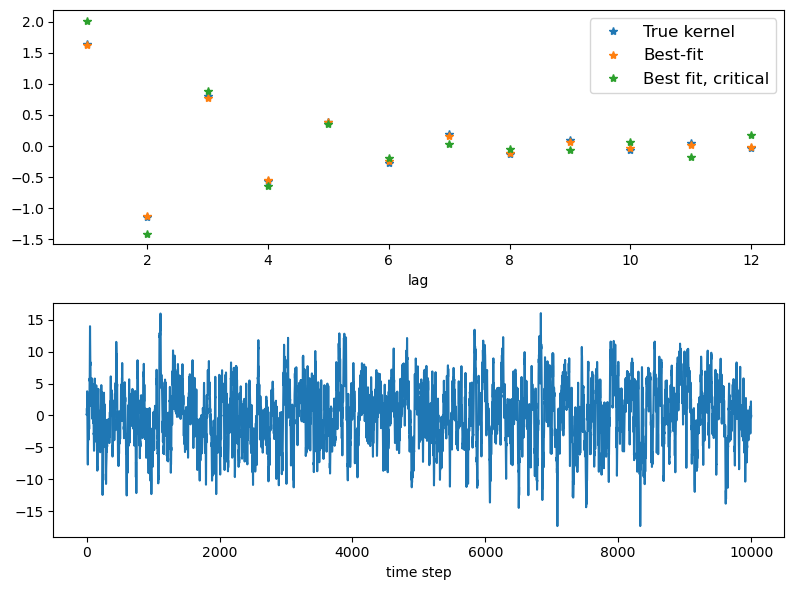

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6))
ax1.plot(lags, kern, "*", label="True kernel")
ax1.plot(lags, kernf, "*", label="Best-fit")
ax1.plot(lags, kernc, "*", label="Best fit, critical")
ax1.set_xlabel("lag")
ax1.legend(fontsize=12)
ax2.plot(np.arange(1, T + 1), x)  # AR data
ax2.set_xlabel("time step")
fig.tight_layout()
# fig.savefig(FIGURES_DIR / "prox_crit_demo_crit_db.png", dpi=150, bbox_inches="tight")